# Double pendulum: friction from energy loss

Input: `measures.csv` from video tracking (first three columns: time and two angles).
Output: plot of total energy with the fitted line on top.

## Theory

Angles are measured from the downward vertical. Moment of inertia of each rod about its own axis comes from its small-oscillation period $t_i$:
$$I_i = m_i g l_i \left(\frac{t_i}{2\pi}\right)^2$$

Total energy:
$$E = \tfrac12 (I_1 + m_2 l_3^2)\omega_1^2 + \tfrac12 I_2\omega_2^2 + m_2 l_3 l_2 \cos(\theta_1-\theta_2)\,\omega_1\omega_2 + m_1 g l_1(1-\cos\theta_1) + m_2 g\left[l_3(1-\cos\theta_1) + l_2(1-\cos\theta_2)\right]$$

Viscous friction: bearing 1 sees $\omega_1$, bearing 2 sees $\omega_2-\omega_1$.
$$\dot E = -c_1\omega_1^2 - c_2(\omega_2-\omega_1)^2$$

Integrate in time:
$$E(t) = E_0 - c_1\int_0^t \omega_1^2\,dt' - c_2\int_0^t (\omega_2-\omega_1)^2\,dt'$$

This is linear in $E_0, c_1, c_2$, so we use a simple linear least-squares fit.

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import curve_fit

DATA_FILE = "measures.csv"
SKIP_ROWS = 5            # 4 comment lines + 1 header line
SMOOTH_WINDOW_S = 0.05   # smoothing window for angles, s
SMOOTH_E_S = 1.0         # smoothing window for energy, s
MOTION_START = 1.0       # fit starts when |omega1| first exceeds this, rad/s

m1, m2 = 0.433, 0.479              # masses, kg
l1, l2, l3 = 0.212, 0.219, 0.255   # l1, l2: axis to centre of mass of rod 1, rod 2; l3: length of rod 1, m
t1, t2 = 1.000, 1.000              # small-oscillation periods of rod 1 and rod 2 alone, s
g = 9.8

In [82]:
# data: time, theta1, theta2 (degrees)
t, th1, th2, w1, w2 = np.genfromtxt(DATA_FILE, delimiter=",", skip_header=5,
                         usecols=(0, 7, 8, 9, 10), unpack=True, encoding="utf-8-sig")
dt = t[1] - t[0]

#w1 *= np.pi / 180
#w2 *= np.pi / 180





# energy
I1 = m1 * g * l1 * (t1 / 2 / np.pi) ** 2
I2 = m2 * g * l2 * (t2 / 2 / np.pi) ** 2
E = (0.5 * (I1 + m2 * l3**2) * w1**2 + 0.5 * I2 * w2**2
     + m2 * l3 * l2 * np.cos(th1 - th2) * w1 * w2
     + m1 * g * l1 * (1 - np.cos(th1))
     + m2 * g * (l3 * (1 - np.cos(th1)) + l2 * (1 - np.cos(th2))))

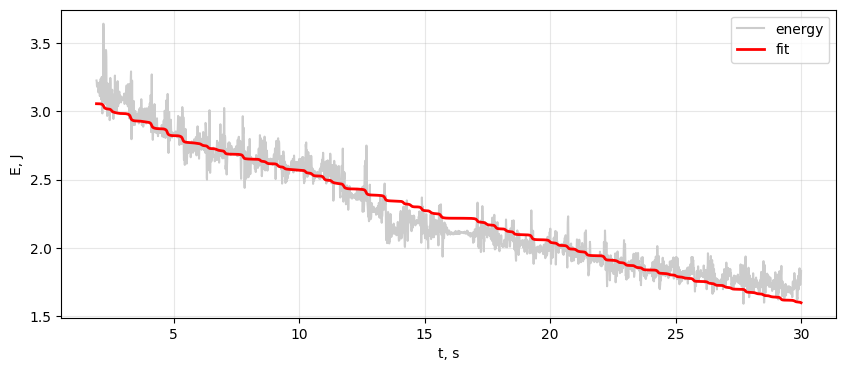

In [92]:
# cut the initial part where the pendulum is at rest
i0 = np.argmax(np.abs(w1) > MOTION_START)
t, w1, w2, E = t[i0:], w1[i0:], w2[i0:], E[i0:]

B1 = cumulative_trapezoid(w1**2, t, initial=0)
B2 = cumulative_trapezoid((w2 - w1)**2, t, initial=0)
B12 = cumulative_trapezoid(w2 * w1, t, initial=0)

# linear fit: Es = E0 - c1*B1 - c2*B2

def viscous_energy_decay(t, c, E0):
  return -c * (B1 + B2) + E0

parameters, pcov = curve_fit(viscous_energy_decay, t, E)

E_fitted = viscous_energy_decay(t, *parameters)

c, E0 = parameters

plt.figure(figsize=(10, 4))
plt.plot(t, E, color="0.8", label="energy")
plt.plot(t, E_fitted, "r", lw=2, label="fit")
plt.xlabel("t, s")
plt.ylabel("E, J")
plt.legend()
plt.grid(alpha=0.3)
#plt.ylim(0, 10)
plt.show()

In [94]:
errs = np.sqrt(np.diag(pcov))

In [95]:
errs

array([1.66134570e-06, 3.53942041e-03])